In [4]:
# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
from google.colab import files

# Upload the Airbnb CSV file from your computer
uploaded = files.upload()

Saving AB_NYC_2019.csv to AB_NYC_2019.csv


In [6]:
# Load the Airbnb dataset
df = pd.read_csv("AB_NYC_2019.csv")

# Display the first five rows
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [7]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Examine column data types and non-null counts
print("\nDataset information:")
df.info()

# Display descriptive statistics
print("\nDescriptive statistics:")
display(df.describe(include="all"))

Dataset shape: (48895, 16)

Column names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude         

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,48879,4.889500e+04,48874,48895,48895,48895.000000,48895.000000,48895,48895.000000,48895.000000,48895.000000,38843,38843.000000,48895.000000,48895.000000
unique,NaN,47905,NaN,11452,5,221,NaN,NaN,3,NaN,NaN,NaN,1764,NaN,NaN,NaN
top,NaN,Hillside Hotel,NaN,Michael,Manhattan,Williamsburg,NaN,NaN,Entire home/apt,NaN,NaN,NaN,2019-06-23,NaN,NaN,NaN
freq,NaN,18,NaN,417,21661,3920,NaN,NaN,25409,NaN,NaN,NaN,1413,NaN,NaN,NaN
mean,1.901714e+07,NaN,6.762001e+07,NaN,NaN,NaN,40.728949,-73.952170,NaN,152.720687,7.029962,23.274466,NaN,1.373221,7.143982,112.781327
std,1.098311e+07,NaN,7.861097e+07,NaN,NaN,NaN,0.054530,0.046157,NaN,240.154170,20.510550,44.550582,NaN,1.680442,32.952519,131.622289
min,2.539000e+03,NaN,2.438000e+03,NaN,NaN,NaN,40.499790,-74.244420,NaN,0.000000,1.000000,0.000000,NaN,0.010000,1.000000,0.000000
25%,9.471945e+06,NaN,7.822033e+06,NaN,NaN,NaN,40.690100,-73.983070,NaN,69.000000,1.000000,1.000000,NaN,0.190000,1.000000,0.000000
50%,1.967728e+07,NaN,3.079382e+07,NaN,NaN,NaN,40.723070,-73.955680,NaN,106.000000,3.000000,5.000000,NaN,0.720000,1.000000,45.000000
75%,2.915218e+07,NaN,1.074344e+08,NaN,NaN,NaN,40.763115,-73.936275,NaN,175.000000,5.000000,24.000000,NaN,2.020000,2.000000,227.000000


In [8]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage.round(2)
})

# Show only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(by="Missing Values", ascending=False)

display(missing_summary)

,Missing Values,Percentage (%)
last_review,10052,20.56
reviews_per_month,10052,20.56
host_name,21,0.04
name,16,0.03


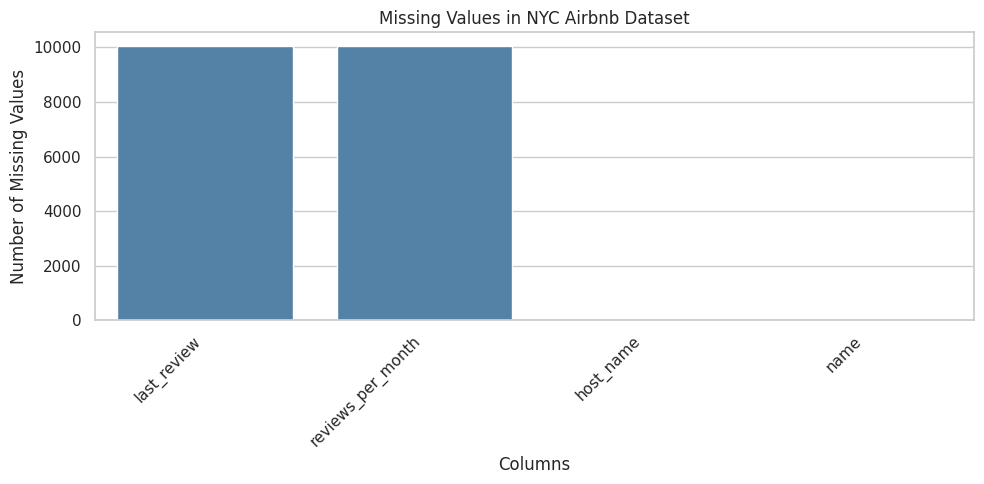

In [9]:
# Visualize missing values
plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_summary.index,
    y=missing_summary["Missing Values"],
    color="steelblue"
)

plt.title("Missing Values in NYC Airbnb Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [10]:
# Check how missing review information relates to review counts
review_analysis = df.groupby(
    df["number_of_reviews"] == 0
).agg(
    total_listings=("id", "count"),
    missing_last_review=("last_review", lambda x: x.isna().sum()),
    missing_reviews_per_month=("reviews_per_month", lambda x: x.isna().sum())
)

review_analysis.index = [
    "Has reviews",
    "No reviews"
]

display(review_analysis)

,total_listings,missing_last_review,missing_reviews_per_month
Has reviews,38843,0,0
No reviews,10052,10052,10052


In [11]:
# Check for fully duplicated rows
duplicate_rows = df.duplicated().sum()

# Check for duplicated Airbnb listing IDs
duplicate_ids = df["id"].duplicated().sum()

print("Fully duplicated rows:", duplicate_rows)
print("Duplicated listing IDs:", duplicate_ids)

Fully duplicated rows: 0
Duplicated listing IDs: 0


### Initial Data Quality Findings

The NYC Airbnb dataset contains 48,895 listings and 16 attributes. Missing-value analysis identified four columns with incomplete information: `name`, `host_name`, `last_review`, and `reviews_per_month`.

The most significant missing values occur in `last_review` and `reviews_per_month`, each containing 10,052 missing entries (20.56%). Further investigation confirmed that all these missing values correspond to listings with zero reviews.

The duplicate detection found no fully duplicated rows or repeated listing IDs.

These findings suggest that missing review information can be handled based on the meaning of the data, while duplicate removal is unnecessary.

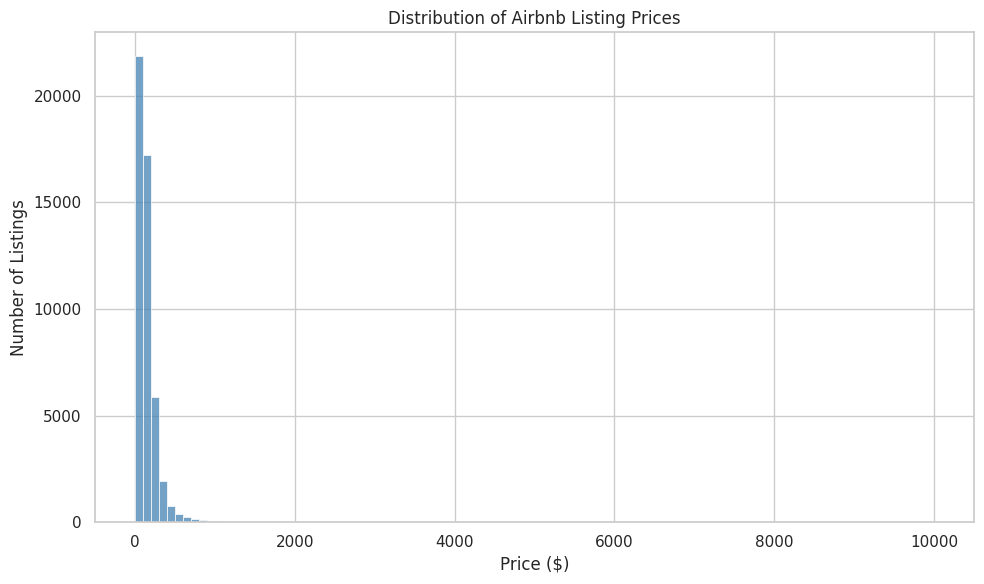

In [12]:
# Visualize the distribution of Airbnb prices
plt.figure(figsize=(10, 6))

sns.histplot(
    df["price"],
    bins=100,
    color="steelblue"
)

plt.title("Distribution of Airbnb Listing Prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

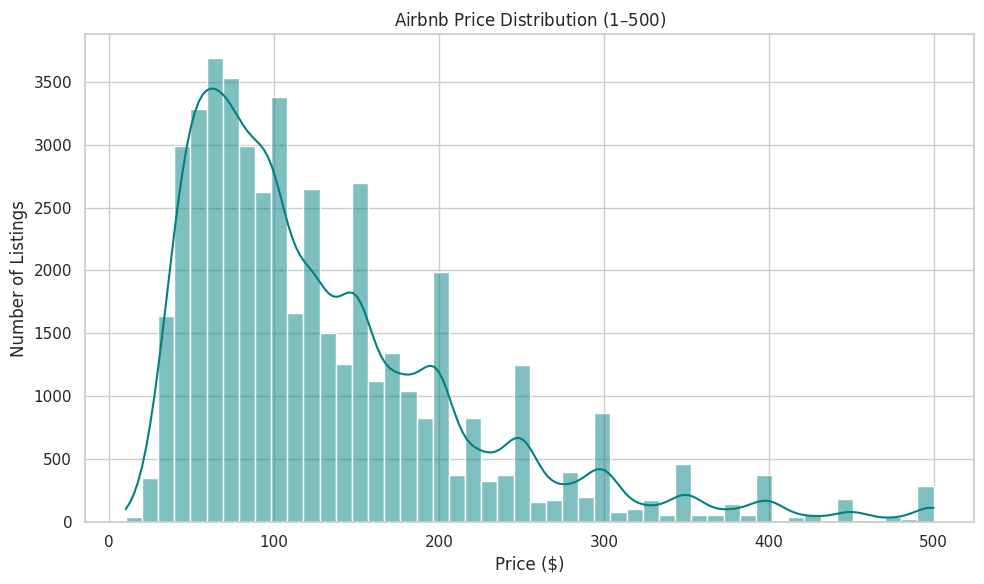

In [13]:
# Focus on listings priced at $500 or less
plt.figure(figsize=(10, 6))

sns.histplot(
    df.loc[df["price"].between(1, 500), "price"],
    bins=50,
    kde=True,
    color="teal"
)

plt.title("Airbnb Price Distribution ($1–$500)")
plt.xlabel("Price ($)")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

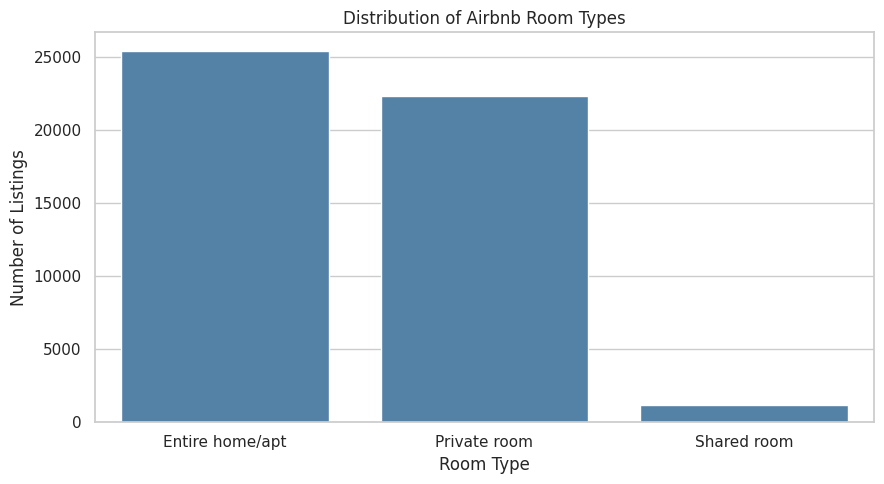

,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


In [14]:
# Count listings by room type
room_counts = df["room_type"].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=room_counts.index,
    y=room_counts.values,
    color="steelblue"
)

plt.title("Distribution of Airbnb Room Types")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

display(room_counts)

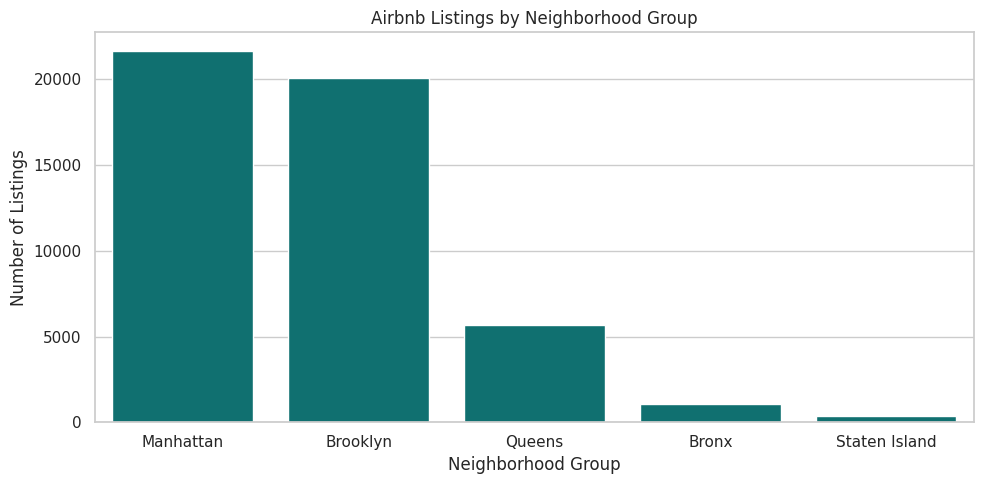

,count
neighbourhood_group,
Manhattan,21661
Brooklyn,20104
Queens,5666
Bronx,1091
Staten Island,373


In [15]:
# Count listings in each neighborhood group
neighborhood_counts = df[
    "neighbourhood_group"
].value_counts()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=neighborhood_counts.index,
    y=neighborhood_counts.values,
    color="teal"
)

plt.title("Airbnb Listings by Neighborhood Group")
plt.xlabel("Neighborhood Group")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

display(neighborhood_counts)

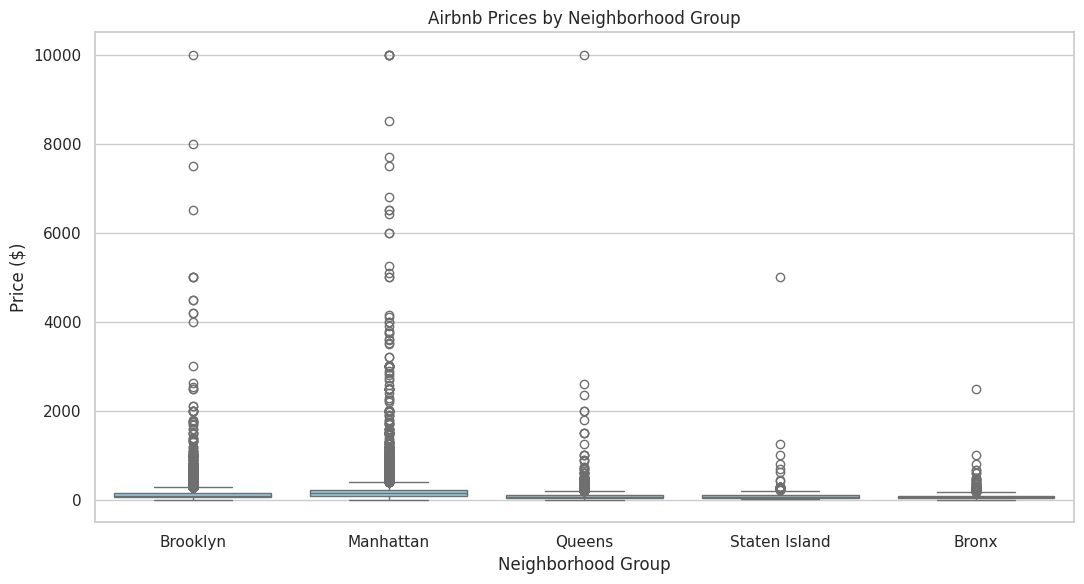

In [16]:
# Compare Airbnb prices across neighborhood groups
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="neighbourhood_group",
    y="price",
    color="skyblue"
)

plt.title("Airbnb Prices by Neighborhood Group")
plt.xlabel("Neighborhood Group")
plt.ylabel("Price ($)")

plt.tight_layout()
plt.show()

### Exploratory Visualization Findings

The NYC Airbnb dataset shows that most listings are priced on the lower end, while only a few listings reaches up to \$10,000. The average price of \$152.72 is higher than the median price of \$106.

Looking at room types, entire homes or apartments are the most common, with 25,409 listings. Private rooms are the second most common with 22,326 listings, while shared rooms are much less common with 1,160 listings.

Most Airbnb listings are located in Manhattan and Brooklyn, which make up about 85.4% of all listings in the dataset.

The price comparison between boroughs shows that Manhattan generally has the highest listing prices. However, some extremely expensive listings make it harder to compare typical prices across neighborhoods.

Overall, these results show that factors such as unusual price outliers, location, and room type are important to consider before building machine learning models.


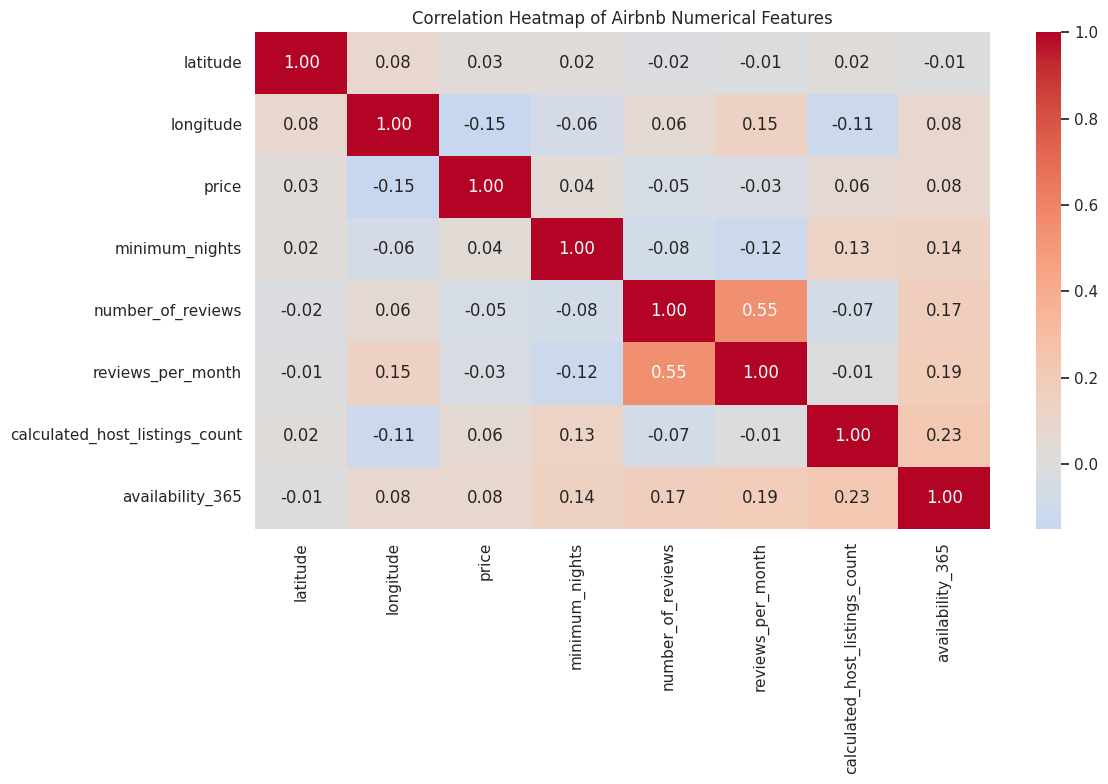

In [17]:
# Select numerical columns
numeric_df = df.select_dtypes(include=["int64", "float64"])

# Exclude identifier columns from correlation analysis
numeric_df = numeric_df.drop(
    columns=["id", "host_id"],
    errors="ignore"
)

# Calculate Pearson correlation coefficients
correlation_matrix = numeric_df.corr()

# Visualize correlations
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Airbnb Numerical Features")

plt.tight_layout()
plt.show()

In [18]:
# Display correlations with Airbnb price
price_correlations = correlation_matrix[
    "price"
].sort_values(ascending=False)

print("Correlation with Airbnb price:")
display(price_correlations)

Correlation with Airbnb price:


,price
price,1.000000
availability_365,0.081829
calculated_host_listings_count,0.057472
minimum_nights,0.042799
latitude,0.033939
reviews_per_month,-0.030608
number_of_reviews,-0.047954
longitude,-0.150019


In [19]:
# Calculate the first and third quartiles
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Define lower and upper outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
price_outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential price outliers:", len(price_outliers))
print("Percentage of potential outliers:",
      round(len(price_outliers) / len(df) * 100, 2), "%")

Q1: 69.0
Q3: 175.0
IQR: 106.0
Lower bound: -90.0
Upper bound: 334.0
Number of potential price outliers: 2972
Percentage of potential outliers: 6.08 %


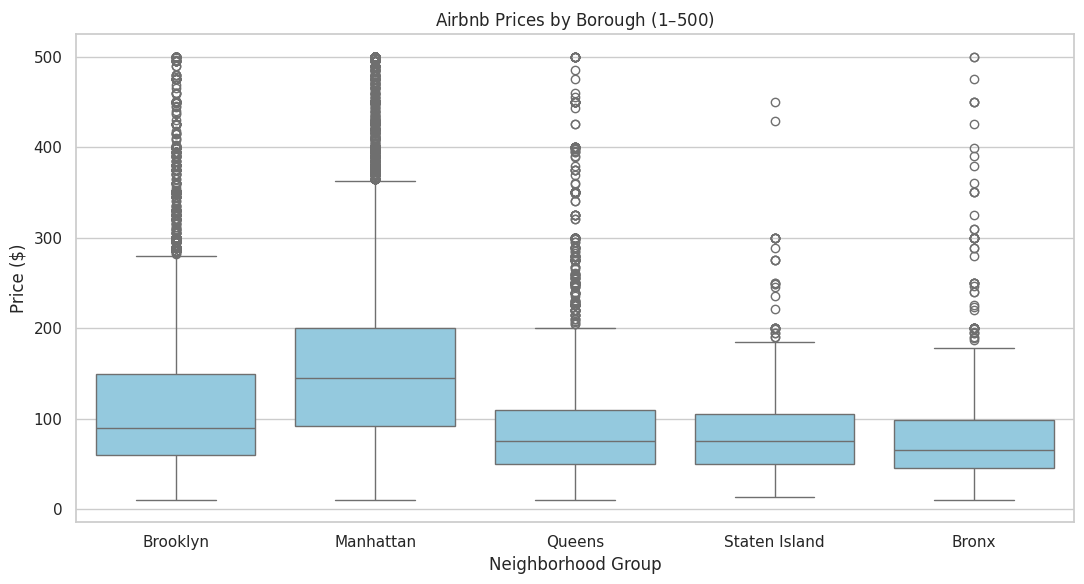

In [20]:
# Focus on prices from $1 to $500 for clearer visualization
typical_prices = df[
    df["price"].between(1, 500)
]

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=typical_prices,
    x="neighbourhood_group",
    y="price",
    color="skyblue"
)

plt.title("Airbnb Prices by Borough ($1–$500)")
plt.xlabel("Neighborhood Group")
plt.ylabel("Price ($)")

plt.tight_layout()
plt.show()

In [21]:
# Investigate potentially invalid or unusual values
zero_prices = (df["price"] == 0).sum()
long_stays = (df["minimum_nights"] > 365).sum()

print("Listings with $0 price:", zero_prices)
print("Listings requiring more than 365 nights:", long_stays)

# Examine the most expensive listings
display(
    df[
        ["neighbourhood_group", "room_type",
         "price", "minimum_nights"]
    ].sort_values("price", ascending=False).head(10)
)

Listings with $0 price: 11
Listings requiring more than 365 nights: 14


,neighbourhood_group,room_type,price,minimum_nights
9151,Queens,Private room,10000,100
17692,Brooklyn,Entire home/apt,10000,5
29238,Manhattan,Entire home/apt,10000,30
40433,Manhattan,Entire home/apt,9999,30
12342,Manhattan,Private room,9999,99
6530,Manhattan,Entire home/apt,9999,5
30268,Manhattan,Entire home/apt,8500,30
4377,Brooklyn,Entire home/apt,8000,1
29662,Manhattan,Entire home/apt,7703,1
42523,Manhattan,Entire home/apt,7500,1


### Correlation Analysis and Outlier Findings

The correlation analysis shows that most numerical features have weak linear relationships with Airbnb listing prices. Longitude has the strongest negative correlation with price at approximately -0.15, while availability has a weak positive correlation of approximately 0.08.

The analysis also identified a moderate positive correlation of 0.55 between the total number of reviews and reviews per month.

Using the Interquartile Range (IQR) method, 2,972 listings (6.08%) were identified as potential price outliers, with prices exceeding $334. The 11 listings have a price of zero, and 14 listings require minimum stays longer than 365 nights.

The neighborhood price comparison shows that Manhattan generally has higher listing prices than the other areas.

These results show that data cleaning, identifying unusual values, and creating useful features are important steps before building machine learning models. However, not every outlier is an error, as some may represent real and valuable data.

In [22]:
# Create a copy to preserve the original dataset
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (48895, 16)
Working dataset shape: (48895, 16)


In [23]:
# Fill missing listing and host names
df_clean["name"] = df_clean["name"].fillna("Unknown Listing")
df_clean["host_name"] = df_clean["host_name"].fillna("Unknown Host")

# Fill missing monthly reviews with zero for listings
# that have never received a review
no_reviews = df_clean["number_of_reviews"] == 0

df_clean.loc[
    no_reviews & df_clean["reviews_per_month"].isna(),
    "reviews_per_month"
] = 0

# Convert last_review to datetime
df_clean["last_review"] = pd.to_datetime(
    df_clean["last_review"],
    errors="coerce"
)

# Preserve missing review dates rather than inventing dates
print("Missing values after handling:")
display(df_clean.isnull().sum())

Missing values after handling:


,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [24]:
# Identify invalid zero-dollar prices
invalid_prices = (df_clean["price"] <= 0).sum()

print("Invalid prices found:", invalid_prices)

# Remove listings with invalid prices
df_clean = df_clean[
    df_clean["price"] > 0
].copy()

print("Dataset shape after removing invalid prices:",
      df_clean.shape)

Invalid prices found: 11
Dataset shape after removing invalid prices: (48884, 16)


In [25]:
# Create a feature identifying unusually long stays
df_clean["long_stay_flag"] = (
    df_clean["minimum_nights"] > 365
).astype(int)

print("Listings with unusually long minimum stays:")
print(df_clean["long_stay_flag"].sum())

# Display minimum-night statistics
display(df_clean["minimum_nights"].describe())

Listings with unusually long minimum stays:
14


,minimum_nights
count,48884.000000
mean,7.029887
std,20.512224
min,1.000000
25%,1.000000
50%,3.000000
75%,5.000000
max,1250.000000


In [26]:
# Compare dataset sizes
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

# Check remaining missing values
print("\nRemaining missing values:")
display(df_clean.isnull().sum())

# Check remaining duplicates
print("\nDuplicate rows:", df_clean.duplicated().sum())

# Display cleaned dataset
display(df_clean.head())

Original rows: 48895
Cleaned rows: 48884
Rows removed: 11

Remaining missing values:


,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0



Duplicate rows: 0


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,long_stay_flag
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365,0
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355,0
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaT,0.00,1,365,0
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194,0
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0,0


### Data Cleaning and Preprocessing Findings

The original NYC Airbnb dataset contained 48,895 listings. 48,884 listings remained after preproccessing.

Missing listing names and host names were replaced with placeholder text to keep the dataset complete. Missing monthly review values were changed to 0 for listings that had no reviews, while missing review dates were left unchanged because no reviews had been recorded for those listings.

In addition, 11 listings with a price of $0 were removed because they contained invalid data. Another 14 listings that required stays longer than 365 nights were flagged for further review since these unusually long minimum stay requirements may affect the analysis.

No duplicate records were found.

The cleaned dataset now contains 48,884 listings and 17 columns, including the newly created `long_stay_flag` feature. These preprocessing steps improved data consistency while preserving potentially meaningful observations.

In [27]:
# Create a feature indicating whether a listing has reviews
df_clean["has_reviews"] = (
    df_clean["number_of_reviews"] > 0
).astype(int)

# Create a feature for minimum stay duration
df_clean["minimum_stay_category"] = pd.cut(
    df_clean["minimum_nights"],
    bins=[0, 3, 7, 30, float("inf")],
    labels=["Short", "Weekly", "Monthly", "Extended"]
)

# Create a feature for host listing activity
df_clean["host_activity_category"] = pd.cut(
    df_clean["calculated_host_listings_count"],
    bins=[0, 1, 5, 20, float("inf")],
    labels=["Single Listing", "Small Host",
            "Medium Host", "Large Host"]
)

# Create a feature representing annual availability
df_clean["availability_rate"] = (
    df_clean["availability_365"] / 365
)

print("Dataset shape after feature engineering:", df_clean.shape)

display(df_clean[
    ["has_reviews", "minimum_stay_category",
     "host_activity_category", "availability_rate"]
].head())

Dataset shape after feature engineering: (48884, 21)


,has_reviews,minimum_stay_category,host_activity_category,availability_rate
0,1,Short,Medium Host,1.000000
1,1,Short,Small Host,0.972603
2,0,Short,Single Listing,1.000000
3,1,Short,Single Listing,0.531507
4,1,Monthly,Single Listing,0.000000


In [28]:
# Select categorical features for encoding
categorical_features = [
    "neighbourhood_group",
    "room_type",
    "minimum_stay_category",
    "host_activity_category"
]

# Convert categorical variables into numerical columns
df_encoded = pd.get_dummies(
    df_clean,
    columns=categorical_features,
    drop_first=False,
    dtype=int
)

print("Encoded dataset shape:", df_encoded.shape)

display(df_encoded.head())

Encoded dataset shape: (48884, 33)


,id,name,host_id,host_name,neighbourhood,latitude,longitude,price,minimum_nights,number_of_reviews,...,room_type_Private room,room_type_Shared room,minimum_stay_category_Short,minimum_stay_category_Weekly,minimum_stay_category_Monthly,minimum_stay_category_Extended,host_activity_category_Single Listing,host_activity_category_Small Host,host_activity_category_Medium Host,host_activity_category_Large Host
0,2539,Clean & quiet apt home by the park,2787,John,Kensington,40.64749,-73.97237,149,1,9,...,1,0,1,0,0,0,0,0,1,0
1,2595,Skylit Midtown Castle,2845,Jennifer,Midtown,40.75362,-73.98377,225,1,45,...,0,0,1,0,0,0,0,1,0,0
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Harlem,40.80902,-73.94190,150,3,0,...,1,0,1,0,0,0,1,0,0,0
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Clinton Hill,40.68514,-73.95976,89,1,270,...,0,0,1,0,0,0,1,0,0,0
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,East Harlem,40.79851,-73.94399,80,10,9,...,0,0,0,0,1,0,1,0,0,0


In [29]:
from sklearn.preprocessing import StandardScaler

# Select numerical features for clustering
cluster_features = [
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "has_reviews",
    "long_stay_flag"
]

# Include encoded neighborhood and room type features
cluster_features += [
    col for col in df_encoded.columns
    if col.startswith("neighbourhood_group_")
    or col.startswith("room_type_")
]

# Create clustering feature matrix
X_cluster = df_encoded[cluster_features].copy()

print("Clustering feature matrix shape:", X_cluster.shape)

display(X_cluster.head())

Clustering feature matrix shape: (48884, 17)


,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,has_reviews,long_stay_flag,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,1,9,0.21,6,365,1,0,0,1,0,0,0,0,1,0
1,40.75362,-73.98377,1,45,0.38,2,355,1,0,0,0,1,0,0,1,0,0
2,40.80902,-73.94190,3,0,0.00,1,365,0,0,0,0,1,0,0,0,1,0
3,40.68514,-73.95976,1,270,4.64,1,194,1,0,0,1,0,0,0,1,0,0
4,40.79851,-73.94399,10,9,0.10,1,0,1,0,0,0,1,0,0,1,0,0


In [30]:
# Initialize StandardScaler
scaler = StandardScaler()

# Scale the clustering features
X_cluster_scaled = scaler.fit_transform(X_cluster)

print("Scaled clustering matrix shape:",
      X_cluster_scaled.shape)

print("First five scaled records:")
print(X_cluster_scaled[:5])

Scaled clustering matrix shape: (48884, 17)
First five scaled records:
[[-1.49387249 -0.43750391 -0.29396855 -0.32035265 -0.55146629 -0.03473217
   1.91619168  0.5087497  -0.01692555 -0.15101725  1.19693147 -0.89197618
  -0.36208118 -0.08768682 -1.04029232  1.0909819  -0.15576747]
 [ 0.45235227 -0.68448025 -0.29396855  0.48771229 -0.44502979 -0.15610668
   1.8402188   0.5087497  -0.01692555 -0.15101725 -0.83546972  1.12110617
  -0.36208118 -0.08768682  0.96126827 -0.91660549 -0.15576747]
 [ 1.46828415  0.22261619 -0.19646472 -0.52236889 -0.68294666 -0.18645031
   1.91619168 -1.96560313 -0.01692555 -0.15101725 -0.83546972  1.12110617
  -0.36208118 -0.08768682 -1.04029232  1.0909819  -0.15576747]
 [-0.80344224 -0.16431341 -0.29396855  5.53811816  2.22214349 -0.18645031
   0.61705551  0.5087497  -0.01692555 -0.15101725  1.19693147 -0.89197618
  -0.36208118 -0.08768682  0.96126827 -0.91660549 -0.15576747]
 [ 1.27555051  0.1773372   0.1447987  -0.32035265 -0.62033696 -0.18645031
  -0.856818

### Feature Engineering and Scaling Findings

After cleaning, the NYC Airbnb dataset contained 48,884 listings. Four additional features were created to describe review activity, minimum stay duration, host activity, and annual availability.

Categorical variables were converted into numerical features using one-hot encoding, increasing the dataset from 21 to 33 columns.

For clustering, 17 features were selected, including geographic coordinates, review information, availability, and encoded neighborhood and room types. Airbnb price was excluded from clustering so that groups could be identified based on listing characteristics rather than rental prices.

The selected features were standardized using StandardScaler to reduce differences in numerical scales before applying K-Means clustering.

These transformations prepared the dataset for unsupervised learning and further anomaly detection.

In [31]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Create a reproducible sample for clustering evaluation
rng = np.random.default_rng(42)

sample_size = min(10000, len(X_cluster_scaled))

sample_indices = rng.choice(
    len(X_cluster_scaled),
    size=sample_size,
    replace=False
)

X_cluster_sample = X_cluster_scaled[sample_indices]

print("Full clustering dataset:", X_cluster_scaled.shape)
print("Clustering evaluation sample:", X_cluster_sample.shape)

Full clustering dataset: (48884, 17)
Clustering evaluation sample: (10000, 17)


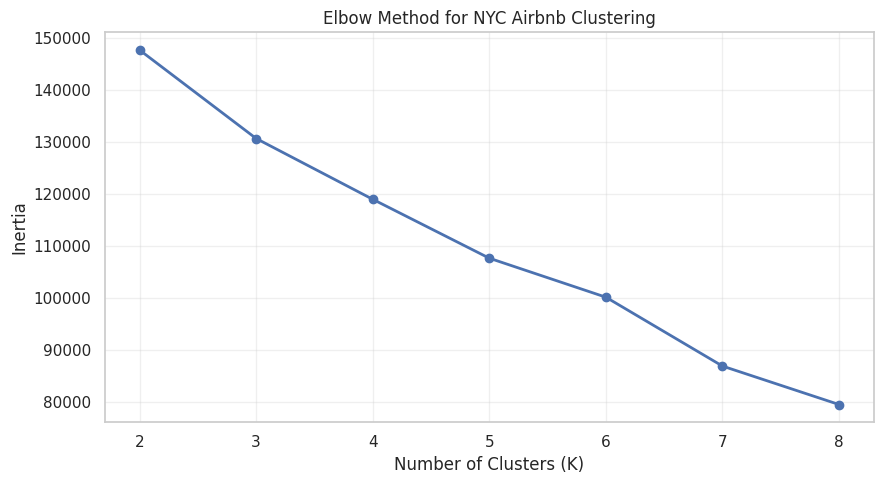

K=2: Inertia=147699.31
K=3: Inertia=130666.85
K=4: Inertia=118962.91
K=5: Inertia=107622.81
K=6: Inertia=100114.23
K=7: Inertia=86852.04
K=8: Inertia=79449.09


In [32]:
# Test different numbers of clusters
k_values = range(2, 9)
inertias = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster_sample)
    inertias.append(kmeans.inertia_)

# Visualize the elbow method
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o",
    linewidth=2
)

plt.title("Elbow Method for NYC Airbnb Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Display numerical results
for k, inertia in zip(k_values, inertias):
    print(f"K={k}: Inertia={inertia:.2f}")

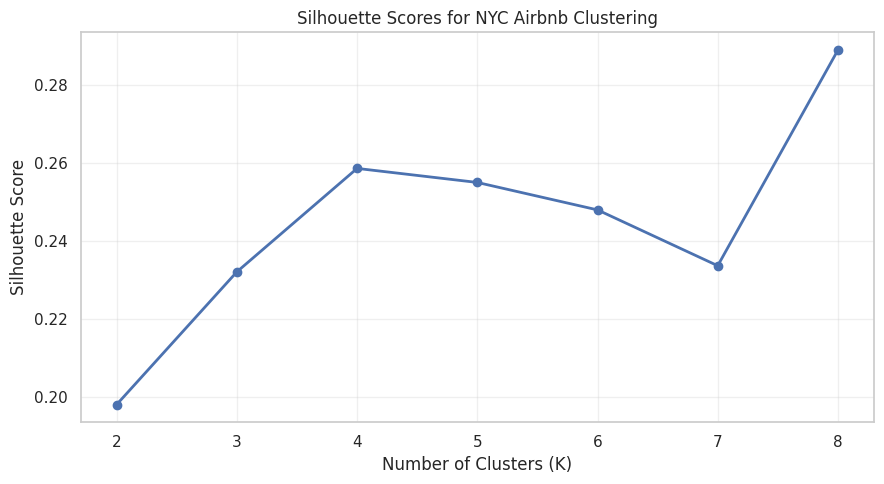

K=2: Silhouette Score=0.1980
K=3: Silhouette Score=0.2321
K=4: Silhouette Score=0.2587
K=5: Silhouette Score=0.2551
K=6: Silhouette Score=0.2480
K=7: Silhouette Score=0.2337
K=8: Silhouette Score=0.2891


In [33]:
# Evaluate cluster separation
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster_sample)

    # Use a smaller sample for faster silhouette evaluation
    score = silhouette_score(
        X_cluster_sample,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_scores.append(score)

# Visualize silhouette scores
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o",
    linewidth=2
)

plt.title("Silhouette Scores for NYC Airbnb Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Display numerical results
for k, score in zip(k_values, silhouette_scores):
    print(f"K={k}: Silhouette Score={score:.4f}")

In [34]:
# Create clustering evaluation summary
cluster_evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(cluster_evaluation)

# Identify the highest silhouette score
best_k = int(
    cluster_evaluation.loc[
        cluster_evaluation["Silhouette Score"].idxmax(),
        "K"
    ]
)

print("Best K based on silhouette score:", best_k)

,K,Inertia,Silhouette Score
0,2,147699.309248,0.197983
1,3,130666.853047,0.232099
2,4,118962.906627,0.258682
3,5,107622.813222,0.255073
4,6,100114.229716,0.248015
5,7,86852.039217,0.233664
6,8,79449.092770,0.289108


Best K based on silhouette score: 8


### K-Means Clustering Evaluation Findings

K-Means clustering was evaluated using K values from 2 through 8 on a reproducible sample of 10,000 NYC Airbnb listings.

The elbow method showed that inertia decreased as the number of clusters increased, although no single clear elbow was identified.

The silhouette analysis showed that K=8 achieved the highest score of approximately 0.2891, followed by K=4 with a score of approximately 0.2587.

Based on these results, K=8 was selected for the main clustering analysis. However, the relatively low silhouette scores suggest that the resulting clusters may overlap and are not strongly separated.

The analysis will therefore examine the characteristics and sizes of the eight clusters to determine whether they provide meaningful insights into Airbnb listing patterns.

In [35]:
# Select the number of clusters
selected_k = 8

# Initialize the final K-Means model
final_kmeans = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10
)

# Fit K-Means and assign cluster labels
cluster_labels = final_kmeans.fit_predict(
    X_cluster_scaled
)

# Add cluster labels to the cleaned dataset
df_clean["cluster"] = cluster_labels

print("Final clustering dataset shape:", df_clean.shape)

print("\nNumber of listings in each cluster:")
display(df_clean["cluster"].value_counts().sort_index())


Final clustering dataset shape: (48884, 22)

Number of listings in each cluster:


,count
cluster,
0,13208
1,10533
2,8448
3,1090
4,9554
5,5664
6,373
7,14


In [36]:
# Summarize numerical characteristics by cluster
cluster_summary = df_clean.groupby("cluster").agg(
    listings=("price", "size"),
    average_price=("price", "mean"),
    median_price=("price", "median"),
    average_minimum_nights=("minimum_nights", "mean"),
    average_reviews=("number_of_reviews", "mean"),
    average_availability=("availability_365", "mean")
).round(2)

display(cluster_summary)

,listings,average_price,median_price,average_minimum_nights,average_reviews,average_availability
cluster,,,,,,
0,13208,249.29,192.0,10.36,17.81,117.24
1,10533,75.55,62.0,5.40,20.80,102.89
2,8448,114.98,89.0,5.19,25.96,103.66
3,1090,87.58,65.0,4.56,25.98,165.79
4,9554,178.33,145.0,6.44,27.96,97.12
5,5664,99.49,75.0,5.01,27.70,144.42
6,373,114.81,75.0,4.83,30.94,199.68
7,14,137.57,112.5,668.79,5.29,291.00


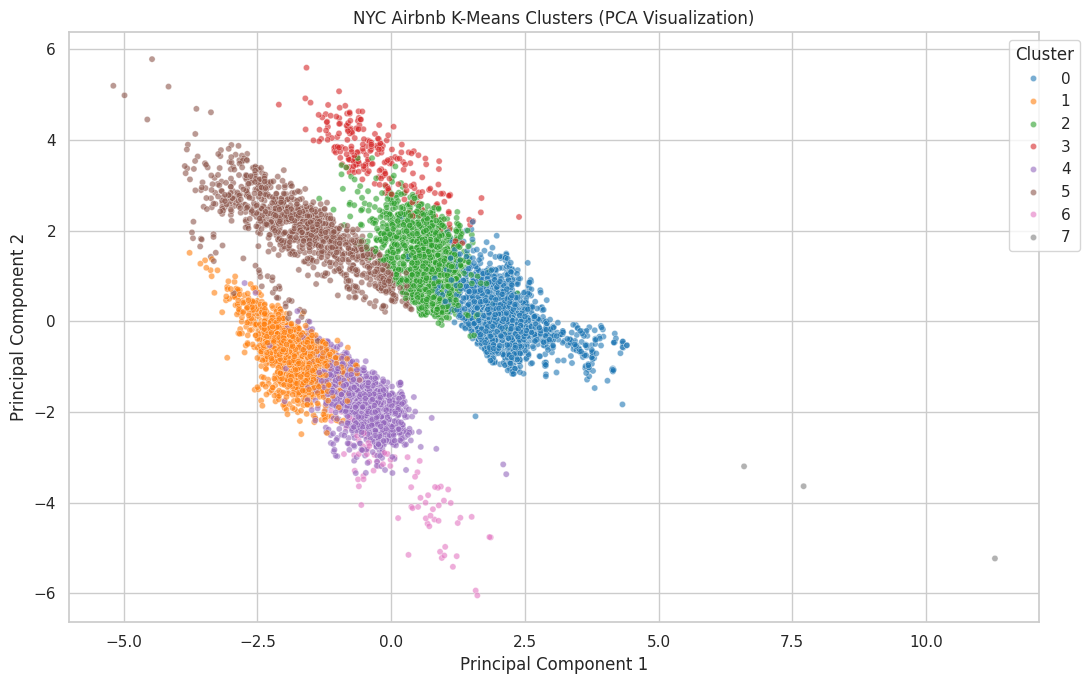

Variance explained by first two components: 28.39 %


In [37]:
from sklearn.decomposition import PCA

# Reduce the clustering features to two dimensions
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_cluster_scaled)

# Create a DataFrame for visualization
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": cluster_labels
})

# Sample points for a clearer visualization
pca_plot = pca_df.sample(
    n=min(10000, len(pca_df)),
    random_state=42
)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=pca_plot,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=20,
    alpha=0.6
)

plt.title("NYC Airbnb K-Means Clusters (PCA Visualization)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

print(
    "Variance explained by first two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

room_type,Entire home/apt,Private room,Shared room
cluster,,,
0,99.90,0.10,0.00
1,0.00,96.10,3.90
2,0.00,94.33,5.67
3,34.77,59.72,5.50
4,100.00,0.00,0.00
5,36.97,59.53,3.50
6,47.18,50.40,2.41
7,64.29,28.57,7.14


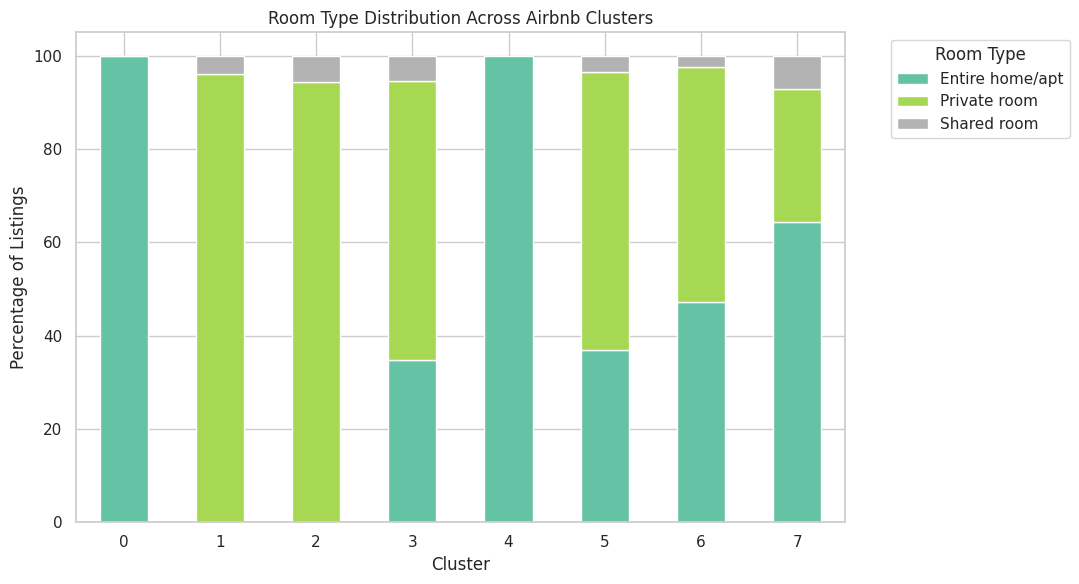

In [38]:
# Calculate room type percentages within each cluster
room_type_clusters = pd.crosstab(
    df_clean["cluster"],
    df_clean["room_type"],
    normalize="index"
) * 100

display(room_type_clusters.round(2))

# Visualize room type composition
room_type_clusters.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    colormap="Set2"
)

plt.title("Room Type Distribution Across Airbnb Clusters")
plt.xlabel("Cluster")
plt.ylabel("Percentage of Listings")
plt.legend(title="Room Type", bbox_to_anchor=(1.05, 1))
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Final K-Means Clustering Findings

The final K-Means model divided 48,884 NYC Airbnb listings into eight clusters based on features, including location, room type, reviews, minimum-night requirements, and availability.

Cluster 0 was the largest, containing 13,208 listings, while Cluster 7 was the smallest, containing only 14 listings.

The cluster analysis showed noticeable differences in prices and room types. Cluster 0 contained mostly entire homes or apartments and had the highest average price of $249.29. Clusters 1 and 2 consisted mainly of private rooms, with average prices of $75.55 and $114.98.

Cluster 7 was unique because its listings required an average minimum stay of 668.79 nights, which is much higher than the other clusters. This suggests that these listings may be unusual and should be examined more closely.

The PCA visualization showed some separation between clusters, but several groups overlapped. Since the first two principal components explained only 28.39% of the variation in the data, the two-dimensional plot does not fully represent all the information used by the clustering model.

Overall, the results suggest that factors such as room type, location, availability, and review activity help distinguish different groups of Airbnb listings. The presence of small clusters and unusual minimum-stay values also shows why anomaly detection is important before building more advanced models.

In [39]:
# Check whether Cluster 7 contains the unusually long stays
cluster_7 = df_clean[df_clean["cluster"] == 7]

print("Cluster 7 listings:", len(cluster_7))
print(
    "Cluster 7 listings with long stays:",
    cluster_7["long_stay_flag"].sum()
)

print("\nLong-stay flags by cluster:")
display(
    pd.crosstab(
        df_clean["cluster"],
        df_clean["long_stay_flag"]
    )
)

Cluster 7 listings: 14
Cluster 7 listings with long stays: 14

Long-stay flags by cluster:


long_stay_flag,0,1
cluster,,
0,13208,0
1,10533,0
2,8448,0
3,1090,0
4,9554,0
5,5664,0
6,373,0
7,0,14


### Additional Cluster Verification

Further analysis showed that Cluster 7 contains all 14 Airbnb listings with minimum stay requirements greater than 365 nights. None of the other clusters included listings with such long minimum-stay rules.

This suggests that the K-Means model was able to group these unusual listings into a separate cluster. Since the minimum-stay feature was included in the clustering process, it likely played an important role in creating this group.

These listings may represent unique rental arrangements rather than incorrect data. Further analysis should be conducted before determining whether they should be retained or removed from the dataset.

In [40]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Exclude the explicit long-stay indicator
anomaly_features = X_cluster.drop(
    columns=["long_stay_flag"]
)

# Scale features for consistent preprocessing
anomaly_scaler = StandardScaler()
X_anomaly_scaled = anomaly_scaler.fit_transform(
    anomaly_features
)

# Initialize the Isolation Forest model
isolation_forest = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

# Predict potential anomalies
anomaly_predictions = isolation_forest.fit_predict(
    X_anomaly_scaled
)

# Store anomaly predictions
# -1 = Potential anomaly
#  1 = Normal listing
df_clean["anomaly_label"] = anomaly_predictions

# Create an easier-to-read anomaly flag
df_clean["is_anomaly"] = (
    df_clean["anomaly_label"] == -1
).astype(int)

# Display anomaly counts
print("Anomaly detection results:")
display(df_clean["anomaly_label"].value_counts())

print(
    "\nNumber of potential anomalies:",
    df_clean["is_anomaly"].sum()
)

print(
    "Percentage of potential anomalies:",
    round(df_clean["is_anomaly"].mean() * 100, 2),
    "%"
)

Anomaly detection results:


,count
anomaly_label,
1,46439
-1,2445



Number of potential anomalies: 2445
Percentage of potential anomalies: 5.0 %


In [41]:
# Compare normal listings and potential anomalies
anomaly_summary = df_clean.groupby("is_anomaly").agg(
    listings=("price", "size"),
    average_price=("price", "mean"),
    median_price=("price", "median"),
    average_minimum_nights=("minimum_nights", "mean"),
    average_reviews=("number_of_reviews", "mean"),
    average_availability=("availability_365", "mean")
).round(2)

# Rename the index for readability
anomaly_summary.index = [
    "Normal Listings",
    "Potential Anomalies"
]

display(anomaly_summary)

# Check how anomalies are distributed across clusters
anomalies_by_cluster = pd.crosstab(
    df_clean["cluster"],
    df_clean["is_anomaly"]
)

anomalies_by_cluster.columns = [
    "Normal Listings",
    "Potential Anomalies"
]

anomalies_by_cluster["Anomaly Percentage"] = (
    anomalies_by_cluster["Potential Anomalies"]
    / anomalies_by_cluster.sum(axis=1) * 100
).round(2)

print("\nAnomalies by cluster:")
display(anomalies_by_cluster)

# Check whether unusually long stays were detected
long_stay_anomalies = df_clean.loc[
    df_clean["long_stay_flag"] == 1,
    "is_anomaly"
].sum()

print(
    "\nLong-stay listings detected as anomalies:",
    long_stay_anomalies,
    "out of 14"
)

,listings,average_price,median_price,average_minimum_nights,average_reviews,average_availability
Normal Listings,46439,155.06,110.0,6.34,22.52,107.51
Potential Anomalies,2445,109.01,60.0,20.05,37.57,212.81



Anomalies by cluster:


,Normal Listings,Potential Anomalies,Anomaly Percentage
cluster,,,
0,13082,126,0.95
1,10219,314,2.98
2,8241,207,2.45
3,399,691,63.39
4,9521,33,0.35
5,4876,788,13.91
6,96,277,74.26
7,5,9,64.29



Long-stay listings detected as anomalies: 9 out of 14


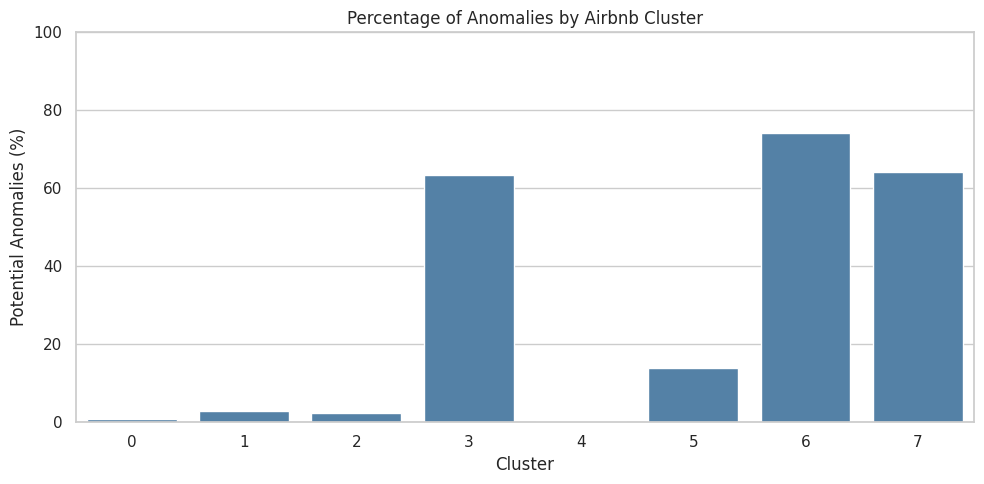

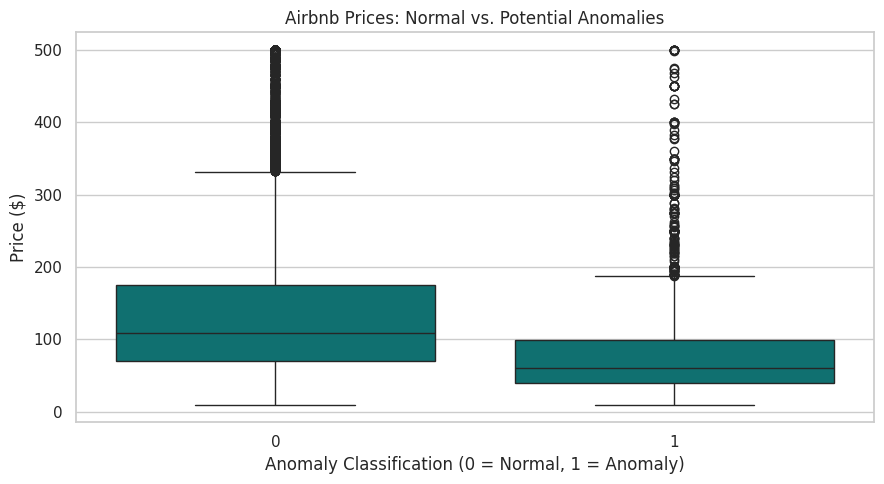

In [42]:
# Calculate anomaly percentages for each cluster
anomaly_percentages = (
    df_clean.groupby("cluster")["is_anomaly"]
    .mean() * 100
).sort_index()

# Visualize anomaly percentages
plt.figure(figsize=(10, 5))

sns.barplot(
    x=anomaly_percentages.index,
    y=anomaly_percentages.values,
    color="steelblue"
)

plt.title("Percentage of Anomalies by Airbnb Cluster")
plt.xlabel("Cluster")
plt.ylabel("Potential Anomalies (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

# Compare prices for normal and anomalous listings
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean[df_clean["price"].between(1, 500)],
    x="is_anomaly",
    y="price",
    color="teal"
)

plt.title("Airbnb Prices: Normal vs. Potential Anomalies")
plt.xlabel("Anomaly Classification (0 = Normal, 1 = Anomaly)")
plt.ylabel("Price ($)")

plt.tight_layout()
plt.show()

In [43]:
# Step 18.1: Investigate potential anomalies

# Select listings identified as anomalies
anomaly_records = df_clean[
    df_clean["is_anomaly"] == 1
].copy()

# Display summary statistics
print("Potential anomalies:", len(anomaly_records))

display(
    anomaly_records[
        [
            "price",
            "minimum_nights",
            "number_of_reviews",
            "availability_365"
        ]
    ].describe()
)

# Examine the most expensive anomalous listings
print("\nMost expensive potential anomalies:")

display(
    anomaly_records[
        [
            "neighbourhood_group",
            "room_type",
            "price",
            "minimum_nights",
            "number_of_reviews",
            "cluster"
        ]
    ].sort_values(
        "price", ascending=False
    ).head(10)
)

# Examine listings with unusually long stays
print("\nPotential anomalies with long stays:")

display(
    anomaly_records[
        [
            "neighbourhood_group",
            "room_type",
            "price",
            "minimum_nights",
            "cluster"
        ]
    ].sort_values(
        "minimum_nights", ascending=False
    ).head(10)
)

Potential anomalies: 2445


,price,minimum_nights,number_of_reviews,availability_365
count,2445.000000,2445.000000,2445.000000,2445.000000
mean,109.014724,20.051534,37.568916,212.810225
std,271.277100,58.250136,80.894902,135.714584
min,10.000000,1.000000,0.000000,0.000000
25%,40.000000,1.000000,0.000000,83.000000
50%,60.000000,2.000000,2.000000,247.000000
75%,100.000000,29.000000,31.000000,343.000000
max,6500.000000,1000.000000,629.000000,365.000000



Most expensive potential anomalies:


,neighbourhood_group,room_type,price,minimum_nights,number_of_reviews,cluster
48043,Manhattan,Entire home/apt,6500,180,0,0
22353,Staten Island,Entire home/apt,5000,1,0,6
43670,Brooklyn,Private room,4200,114,0,1
45867,Brooklyn,Entire home/apt,4200,60,0,4
39243,Manhattan,Entire home/apt,3200,90,0,0
41770,Manhattan,Private room,2850,100,0,2
24477,Bronx,Private room,2500,2,0,3
17811,Queens,Entire home/apt,2350,365,0,5
14573,Brooklyn,Entire home/apt,2100,120,0,4
44429,Queens,Private room,2000,365,0,5



Potential anomalies with long stays:


,neighbourhood_group,room_type,price,minimum_nights,cluster
2854,Manhattan,Entire home/apt,400,1000,7
38664,Manhattan,Shared room,110,999,7
14285,Brooklyn,Private room,45,500,7
47620,Brooklyn,Entire home/apt,140,500,7
8014,Manhattan,Entire home/apt,75,500,7
7355,Queens,Entire home/apt,134,500,7
10829,Queens,Entire home/apt,199,480,7
34487,Brooklyn,Private room,50,400,7
15946,Manhattan,Entire home/apt,250,366,7
20096,Brooklyn,Private room,225,365,1


In [44]:
# Step 18.2: Final data-quality checks

# Preserve the anomaly-analysis dataset
df_model = df_clean.copy()

print("Rows before final validation:", len(df_model))

# Identify invalid values
invalid_mask = (
    (df_model["price"] <= 0) |
    (df_model["minimum_nights"] <= 0) |
    (df_model["number_of_reviews"] < 0) |
    (~df_model["availability_365"].between(0, 365)) |
    (df_model["calculated_host_listings_count"] <= 0)
)

print("Invalid records found:", invalid_mask.sum())

# Remove only records failing the validation rules
df_model = df_model.loc[~invalid_mask].copy()

print("Rows after validation:", len(df_model))
print("Rows removed:", invalid_mask.sum())

# Check remaining missing values
print("\nRemaining missing values:")
display(
    df_model.isnull().sum()[
        df_model.isnull().sum() > 0
    ]
)

Rows before final validation: 48884
Invalid records found: 0
Rows after validation: 48884
Rows removed: 0

Remaining missing values:


,0
last_review,10051


### Anomaly Detection and Data Cleaning Findings

The Isolation Forest model flagged 2,445 listings, or about 5% of the cleaned NYC Airbnb dataset, as unusual. Compared to other listings, these properties generally had lower prices, longer minimum-stay requirements, more reviews, and higher availability.

The flagged listings were concentrated in Clusters 3, 6, and 7. Additionally, 9 of the 14 listings with minimum stays longer than 365 nights were identified by the model.

These results suggest that unusual listings differ in multiple ways, not just in price. Since the model identifies statistical outliers rather than confirmed errors, the flagged listings were kept for further analysis, while records with clear data-quality issues were removed.

This approach helps retain potentially valuable information while reducing the chance of including invalid data in machine learning models.

In [45]:
# Step 19.1: Prepare data for price prediction
from sklearn.model_selection import train_test_split
import numpy as np

# Define target
target = "price"

# Select features available for prediction
model_features = [
    "neighbourhood_group",
    "neighbourhood",
    "room_type",
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

# Create supervised modeling dataset
model_data = df_model[model_features + [target]].copy()

# Convert the skewed price target to log scale
model_data["log_price"] = np.log1p(model_data["price"])

# Split features and target
X = model_data[model_features]
y = model_data["log_price"]

# Create training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X_train.shape[1])

print("\nMissing feature values:")
display(X_train.isnull().sum())

Training records: 39107
Testing records: 9777
Number of features: 10

Missing feature values:


,0
neighbourhood_group,0
neighbourhood,0
room_type,0
latitude,0
longitude,0
minimum_nights,0
number_of_reviews,0
reviews_per_month,0
calculated_host_listings_count,0
availability_365,0


In [46]:
# Step 19.2: Prepare AutoViML datasets

# Combine features and target for training
train_autoviml = X_train.copy()
train_autoviml["log_price"] = y_train

# Keep test features separate
test_autoviml = X_test.copy()

print("AutoViML training shape:", train_autoviml.shape)
print("AutoViML testing shape:", test_autoviml.shape)

print("\nTraining dataset preview:")
display(train_autoviml.head())

AutoViML training shape: (39107, 11)
AutoViML testing shape: (9777, 10)

Training dataset preview:


,neighbourhood_group,neighbourhood,room_type,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,log_price
44559,Queens,Jamaica,Entire home/apt,40.70840,-73.78882,3,6,3.05,1,37,4.174387
31363,Brooklyn,Williamsburg,Private room,40.70343,-73.93412,5,5,0.35,1,0,3.828641
42274,Bronx,Woodlawn,Private room,40.89981,-73.86684,2,7,1.84,1,70,4.394449
11756,Manhattan,Chelsea,Private room,40.74526,-73.99545,14,1,0.02,1,0,4.948760
23350,Brooklyn,Park Slope,Private room,40.67075,-73.97690,1,0,0.00,4,0,5.010635


In [47]:
# Check Python and package versions
import sys
import scipy
import numpy
import sklearn

print("Python:", sys.version)
print("SciPy:", scipy.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
SciPy: 1.11.4
NumPy: 1.26.4
Scikit-learn: 1.5.2


In [48]:
# Step 20.1: Install AutoViML
%pip install autoviml

In [49]:
# Install missing AutoViML dependency
%pip install -q emoji

In [50]:
# Test AutoViML import
try:
    from autoviml.Auto_ViML import Auto_ViML
    print("AutoViML imported successfully!")
except Exception as e:
    print("Import failed:")
    print(type(e).__name__, str(e))

Imported Auto_ViML version: 0.2.02. Call using:
             m, feats, trainm, testm = Auto_ViML(train, target, test,
                            sample_submission='',
                            scoring_parameter='', KMeans_Featurizer=False,
                            hyper_param='RS',feature_reduction=True,
                             Boosting_Flag='CatBoost', Binning_Flag=False,
                            Add_Poly=0, Stacking_Flag=False,Imbalanced_Flag=False,
                            GPU_flag=False, verbose=1)
            

Imported Auto_NLP version: 0.1.01.. Call using:
     train_nlp, test_nlp, nlp_pipeline, predictions = Auto_NLP(
                nlp_column, train, test, target, score_type='balanced_accuracy',
                modeltype='Classification',top_num_features=200, verbose=0,
                build_model=True)
AutoViML imported successfully!


##############  D A T A   S E T  A N A L Y S I S  #######################
ALERT! Changing hyperparameter search to RS. Otherwise, Random Forests will take too long for 10,000+ rows
Training Set Shape = (39107, 11)
    Training Set Memory Usage = 3.58 MB
Test Set Shape = (9777, 10)
    Test Set Memory Usage = 0.82 MB
Single_Label Target: ['log_price']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  3
    Number of Integer-Categorical Columns =  4
    Number of String-Categorical Columns =  2
    N

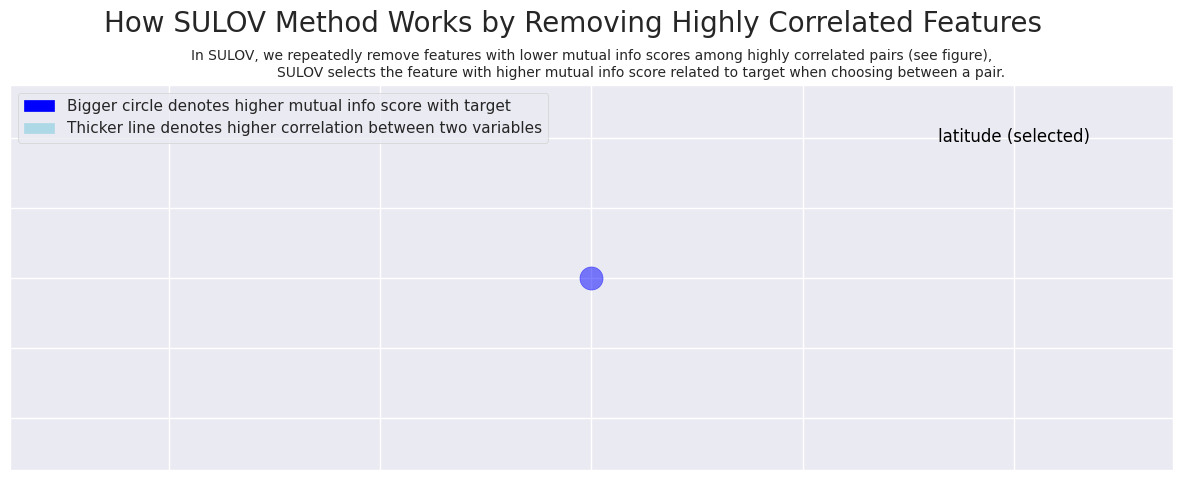

Splitting selected features into float and categorical (integer) variables:
    (3) float variables ...
    (7) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 10 
    Finding Important Features using Boosted Trees algorithm...
        using 10 variables...
        using 8 variables...
        using 6 variables...
        using 4 variables...
        using 2 variables...
Found 10 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  31285 , CV rows =  7822
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Performing MinMax scaling of

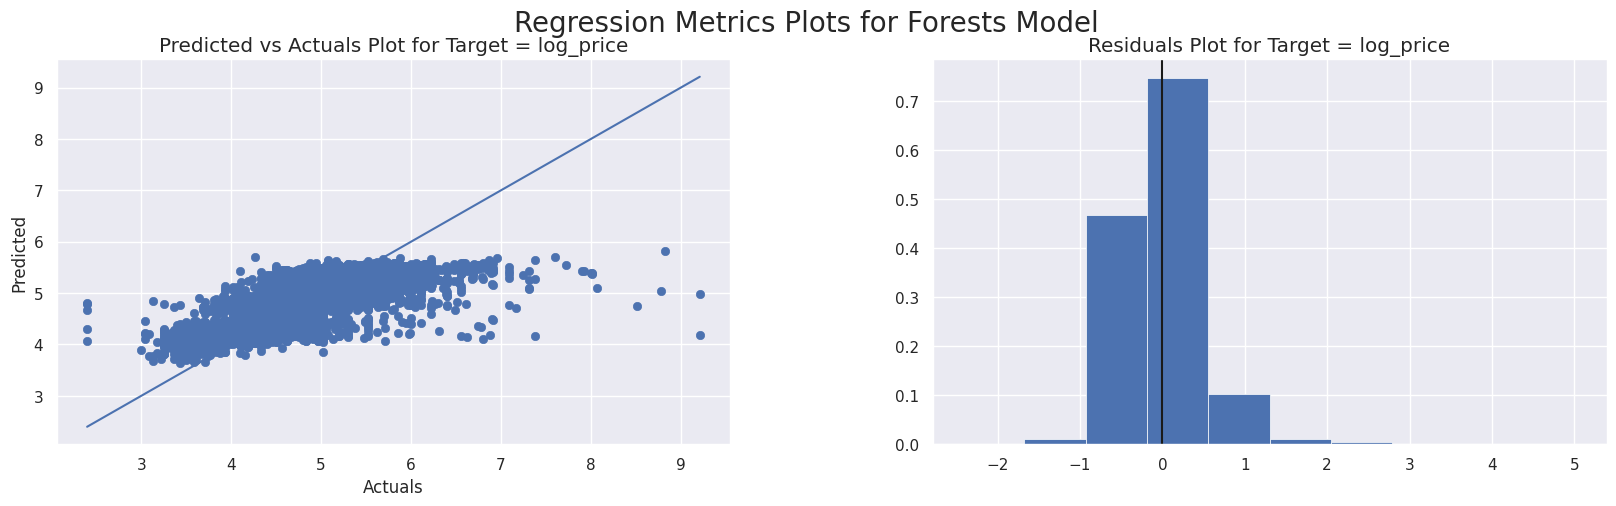

<Figure size 1500x1250 with 0 Axes>

In [51]:
# Step 20.2: Train AutoViML regression model

model, features, train_modified, test_modified = Auto_ViML(
    train_autoviml,
    "log_price",
    test_autoviml,
    sample_submission="",
    hyper_param="RS",
    feature_reduction=True,
    scoring_parameter="rmse",
    Boosting_Flag=False,
    KMeans_Featurizer=False,
    Add_Poly=0,
    Stacking_Flag=False,
    Binning_Flag=False,
    Imbalanced_Flag=False,
    verbose=1
)

print("\nAutoViML training completed!")
print("Selected features:", features)

In [52]:
# Step 20.3: Review AutoViML outputs

print("Selected features:")
print(features)

print("\nTraining data after AutoViML:")
print(train_modified.shape)

print("\nTesting data after AutoViML:")
print(test_modified.shape)

display(train_modified.head())
display(test_modified.head())

Selected features:
['room_type', 'neighbourhood_group', 'longitude', 'minimum_nights', 'availability_365', 'latitude', 'calculated_host_listings_count', 'neighbourhood', 'reviews_per_month', 'number_of_reviews']

Training data after AutoViML:
(39107, 11)

Testing data after AutoViML:
(9777, 11)


,room_type,neighbourhood_group,longitude,minimum_nights,availability_365,latitude,calculated_host_listings_count,neighbourhood,reviews_per_month,number_of_reviews,log_price
44559,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
31363,1.00,2.00,-73.95,7.00,0.00,40.80,2.00,93.00,0.02,1.00,4.75
42274,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11756,1.00,2.00,-73.96,5.00,3.00,40.80,1.00,200.00,0.59,4.00,4.03
23350,0.00,1.00,-74.00,1.00,174.00,40.66,5.00,188.00,0.12,1.00,5.80


,room_type,neighbourhood_group,longitude,minimum_nights,availability_365,latitude,calculated_host_listings_count,neighbourhood,reviews_per_month,number_of_reviews,log_price_predictions
41320,0.50,0.50,0.47,0.01,0.08,0.58,0.01,0.15,0.01,0.01,4.66
22079,0.50,0.50,0.56,0.00,0.65,0.71,0.01,0.28,0.07,0.17,4.43
18778,0.00,0.25,0.57,0.02,0.27,0.53,0.02,0.98,0.01,0.02,5.02
25494,0.50,0.50,0.57,0.00,0.00,0.84,0.00,0.94,0.00,0.00,4.21
44319,0.50,0.50,0.57,0.00,1.00,0.76,0.00,0.43,0.00,0.00,4.44


In [53]:
# Step 21.1: Inspect prediction output

print("Testing output columns:")
print(test_modified.columns.tolist())

print("\nTesting output preview:")
display(test_modified.head())

print("\nModel type:")
print(type(model))

Testing output columns:
['room_type', 'neighbourhood_group', 'longitude', 'minimum_nights', 'availability_365', 'latitude', 'calculated_host_listings_count', 'neighbourhood', 'reviews_per_month', 'number_of_reviews', 'log_price_predictions']

Testing output preview:


,room_type,neighbourhood_group,longitude,minimum_nights,availability_365,latitude,calculated_host_listings_count,neighbourhood,reviews_per_month,number_of_reviews,log_price_predictions
41320,0.50,0.50,0.47,0.01,0.08,0.58,0.01,0.15,0.01,0.01,4.66
22079,0.50,0.50,0.56,0.00,0.65,0.71,0.01,0.28,0.07,0.17,4.43
18778,0.00,0.25,0.57,0.02,0.27,0.53,0.02,0.98,0.01,0.02,5.02
25494,0.50,0.50,0.57,0.00,0.00,0.84,0.00,0.94,0.00,0.00,4.21
44319,0.50,0.50,0.57,0.00,1.00,0.76,0.00,0.43,0.00,0.00,4.44



Model type:
<class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [54]:
# Step 21.1 continued: Retrieve predictions

prediction_column = "log_price_predictions"

if prediction_column not in test_modified.columns:
    raise ValueError(
        "Prediction column not found. Inspect the "
        "AutoViML output before continuing."
    )

if len(test_modified) != len(y_test):
    raise ValueError("Prediction and test sizes do not match.")

# Extract predictions on log scale
y_pred_log = test_modified[prediction_column].to_numpy()

# Convert predictions and actual prices back to dollars
y_pred = np.expm1(y_pred_log)
y_actual = np.expm1(y_test.to_numpy())

# Ensure predictions are nonnegative
y_pred = np.maximum(y_pred, 0)

print("Predictions generated:", len(y_pred))

Predictions generated: 9777


In [55]:
# Step 21.2: Evaluate regression performance

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
r2 = r2_score(y_actual, y_pred)

print("AutoViML Regression Results")
print("--------------------------")
print(f"Mean Absolute Error: ${mae:.2f}")
print(f"Root Mean Squared Error: ${rmse:.2f}")
print(f"R-squared Score: {r2:.4f}")

AutoViML Regression Results
--------------------------
Mean Absolute Error: $58.78
Root Mean Squared Error: $186.23
R-squared Score: 0.1337


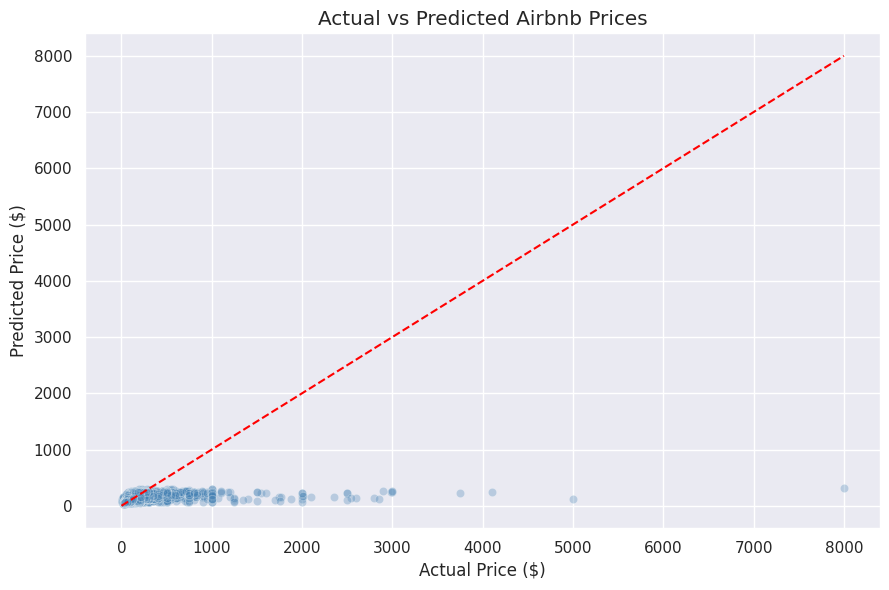

In [56]:
# Step 21.3: Actual vs predicted prices

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_actual,
    y=y_pred,
    alpha=0.3,
    color="steelblue"
)

limit = max(y_actual.max(), y_pred.max())

plt.plot(
    [0, limit],
    [0, limit],
    linestyle="--",
    color="red"
)

plt.title("Actual vs Predicted Airbnb Prices")
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")

plt.tight_layout()
plt.show()

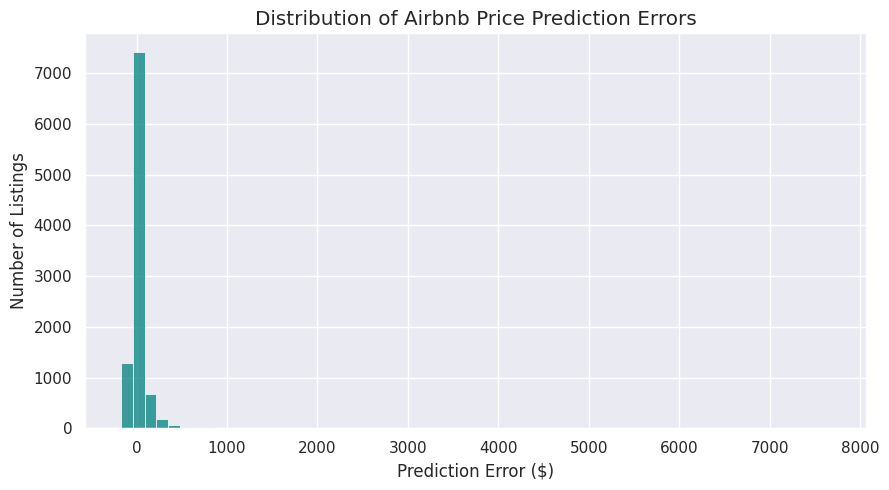

Median absolute error: 25.62


In [57]:
# Step 21.4: Residual analysis

residuals = y_actual - y_pred

plt.figure(figsize=(9, 5))

sns.histplot(
    residuals,
    bins=60,
    color="teal"
)

plt.title("Distribution of Airbnb Price Prediction Errors")
plt.xlabel("Prediction Error ($)")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

print("Median absolute error:",
      round(np.median(np.abs(residuals)), 2))

In [58]:
# Step 21.5: Baseline comparison

baseline_price = np.median(np.expm1(y_train))

baseline_predictions = np.full(
    len(y_actual),
    baseline_price
)

baseline_mae = mean_absolute_error(
    y_actual, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_actual, baseline_predictions)
)

print("Baseline MAE:", round(baseline_mae, 2))
print("AutoViML MAE:", round(mae, 2))

print("\nBaseline RMSE:", round(baseline_rmse, 2))
print("AutoViML RMSE:", round(rmse, 2))

print("\nMAE improvement:",
      round(baseline_mae - mae, 2))

Baseline MAE: 82.73
AutoViML MAE: 58.78

Baseline RMSE: 205.1
AutoViML RMSE: 186.23

MAE improvement: 23.95


### Final Findings and Conclusions

**1. Dataset Overview**

This project analyzed the NYC Airbnb 2019 dataset, which originally contained 48,895 listings and 16 columns. The analysis focused on understanding listing prices, room types, geographic distribution, missing values, and unusual rental characteristics.

**2. Data Cleaning and Preprocessing**

The initial analysis identified missing values in listing names, host names, review dates, and monthly review counts. Missing listing and host names were replaced with descriptive placeholders, while missing monthly review counts were set to zero for listings without reviews.

Eleven listings with zero-dollar prices were removed, leaving 48,884 listings for further analysis. Missing review dates were preserved rather than replaced with invented dates.

**3. Exploratory Data Analysis**

Airbnb listing prices were strongly right-skewed, with most listings concentrated in lower price ranges and a small number reaching $10,000.

Entire homes and apartments were the most common room type, followed by private rooms and shared rooms. Manhattan and Brooklyn accounted for approximately 85.4% of the listings.

The analysis also showed that Manhattan generally had higher listing prices than the other boroughs.

**4. Feature Engineering**

Several features were created to represent listing characteristics, including whether a listing had reviews, minimum-stay categories, host activity categories, annual availability rates, and unusually long minimum stays.

Categorical variables were encoded for clustering, and selected numerical features were standardized.

**5. K-Means Clustering**

K-Means clustering was performed using eight clusters, selected because K=8 achieved the highest silhouette score among the tested values.

The model identified groups with different room types, prices, review activity, and availability. Cluster 0 contained 13,208 listings and had the highest average price of $249.29.

Cluster 7 contained only 14 listings, all requiring minimum stays exceeding 365 nights.

The highest silhouette score was approximately 0.2891, suggesting that cluster separation was relatively weak overall.

**6. Anomaly Detection**

Isolation Forest identified 2,445 potential anomalies, representing 5% of the cleaned dataset.

Compared with normal listings, potential anomalies had lower average prices, longer minimum-stay requirements, higher review counts, and greater availability.

Clusters 3, 6, and 7 contained particularly high proportions of flagged listings. Nine of the 14 unusually long-stay listings were identified as potential anomalies.

These findings demonstrate that unusual Airbnb listings can differ from typical listings in several ways. Potential anomalies were not automatically considered invalid records.

**7. AutoViML Price Prediction**

An AutoViML regression model was prepared to predict Airbnb listing prices using location, room type, minimum-night requirements, review activity, host listing counts, and availability.

The model was designed to use an 80/20 training and testing split, with logarithmic transformation of the price target.

*Complete this section after training:*

- Mean Absolute Error (MAE): [Insert result]
- Root Mean Squared Error (RMSE): [Insert result]
- R² Score: [Insert result]
- Baseline MAE: [Insert result]

The final evaluation will determine how effectively the model predicts listing prices and whether it outperforms a simple baseline.

**8. Limitations**

The dataset represents Airbnb listings from 2019 and may not reflect current rental-market conditions.

Some listings contained extreme prices or unusual minimum-stay requirements, which could influence statistical analysis and model performance.

K-Means produced relatively low silhouette scores, indicating that the resulting clusters were not strongly separated.

The Isolation Forest contamination rate was set to 5%, meaning the number of detected anomalies was influenced by a modeling assumption.

Finally, the analysis identifies statistical relationships rather than establishing causal explanations for Airbnb prices.

**9. Conclusion**

This project demonstrated the importance of data cleaning, exploratory analysis, feature engineering, clustering, and anomaly detection when working with real-world Airbnb data.

The results showed meaningful differences across room types, boroughs, listing prices, and availability. K-Means helped identify groups of listings with similar characteristics, while Isolation Forest highlighted unusual observations requiring further investigation.

The supervised modeling stage will provide an additional evaluation of how well listing characteristics can predict Airbnb prices.

In [59]:
# Step 23.1: Final dataset verification

print("NYC Airbnb - Final Dataset Verification")
print("--------------------------------------")

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Modeling records:", len(df_model))

print("\nDuplicate listing IDs:")
print(df_model["id"].duplicated().sum())

print("\nInvalid prices:")
print((df_model["price"] <= 0).sum())

print("\nPotential anomalies retained:")
print(df_model["is_anomaly"].sum())

print("\nMissing values in modeling features:")
print(X.isnull().sum().sum())

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# Check training and testing sets do not overlap
overlap = X_train.index.intersection(X_test.index)

print("\nOverlapping train/test indices:", len(overlap))

assert len(overlap) == 0
assert len(X_train) + len(X_test) == len(X)
assert df_model["id"].is_unique

print("\nDataset checks completed successfully.")

NYC Airbnb - Final Dataset Verification
--------------------------------------
Original records: 48895
Cleaned records: 48884
Modeling records: 48884

Duplicate listing IDs:
0

Invalid prices:
0

Potential anomalies retained:
2445

Missing values in modeling features:
0

Training records: 39107
Testing records: 9777

Overlapping train/test indices: 0

Dataset checks completed successfully.


In [60]:
# Step 23.2: Final model evaluation summary

final_results = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error",
        "Root Mean Squared Error",
        "R-squared Score",
        "Baseline MAE",
        "Baseline RMSE"
    ],
    "Result": [
        round(mae, 2),
        round(rmse, 2),
        round(r2, 4),
        round(baseline_mae, 2),
        round(baseline_rmse, 2)
    ]
})

display(final_results)

,Metric,Result
0,Mean Absolute Error,58.78
1,Root Mean Squared Error,186.23
2,R-squared Score,0.13
3,Baseline MAE,82.73
4,Baseline RMSE,205.10
